# Unemployment Analysis with Python
**Author:** Syed Aon Muhammad Kazmi  
**Track:** Data Science | OASIS INFOBYTE

## Objective and data
Data: Unemployment in India, May 2019–June 2020, public mirror https://github.com/aksp42/unemployment-india-analysis/blob/main/Unemployment%20in%20India.csv. Original dataset: https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india. Observational analysis, not causal estimation.

Reproducible seed: 42. Model selection uses cross-validation on training data; the held-out test set is evaluated once per candidate for reporting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
def save(name):
    plt.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def inspect(df):
    print('Shape:', df.shape)
    display(df.head(), df.dtypes.to_frame('dtype'), df.isna().sum().to_frame('missing'), df.describe(include='all'))


In [2]:
df=pd.read_csv('data/unemployment.csv');df.columns=df.columns.str.strip();inspect(df)
print('Entirely empty rows:',df.isna().all(axis=1).sum())
df=df.dropna(how='all').drop_duplicates().copy()
df['Date']=pd.to_datetime(df['Date'].str.strip(),dayfirst=True)
for col in ['Region','Area']: df[col]=df[col].str.strip()
rate='Estimated Unemployment Rate (%)'; participation='Estimated Labour Participation Rate (%)'
for col in [rate,participation,'Estimated Employed']: df[col]=pd.to_numeric(df[col],errors='coerce')
df=df.dropna(subset=['Date','Region',rate,participation])
assert df[rate].between(0,100).all() and df[participation].between(0,100).all()
print('Clean shape:',df.shape,'Date range:',df.Date.min(),df.Date.max())
# Derived share of working-age population employed, assuming compatible definitions.
df['Derived employment-population rate (%)']=df[participation]*(1-df[rate]/100)

Shape: (768, 7)
Entirely empty rows: 28
Clean shape: (740, 7) Date range: 2019-05-31 00:00:00 2020-06-30 00:00:00


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


,dtype
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object


,missing
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


## Regional averages
These are unweighted averages of available region/area/month observations. They are descriptive comparisons, not an official population-weighted national unemployment rate. Missing observations and unequal regional coverage can affect rankings.

Highest mean: Tripura 28.35


,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


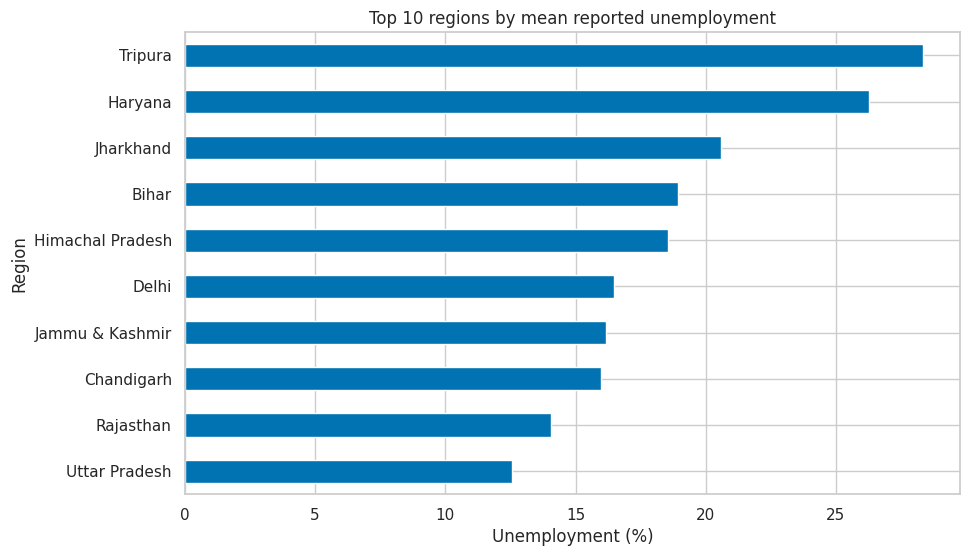

In [3]:
regional=df.groupby('Region')[rate].mean().sort_values(ascending=False)
display(regional.to_frame());regional.to_csv(OUT/'regional_averages.csv')
regional.head(10).sort_values().plot.barh(figsize=(10,6),title='Top 10 regions by mean reported unemployment');plt.xlabel('Unemployment (%)');save('top10_regions')
print('Highest mean:',regional.index[0],round(regional.iloc[0],2))

**Observation:** The highest unweighted regional mean is Tripura (28.35%).

## Monthly trends
The time series below averages available rural/urban observations within each state and month. Compare movement over time; the available series is short and cannot establish recurring seasonality.

Peak observed month: 2020-05-31 Mean: 24.88


,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


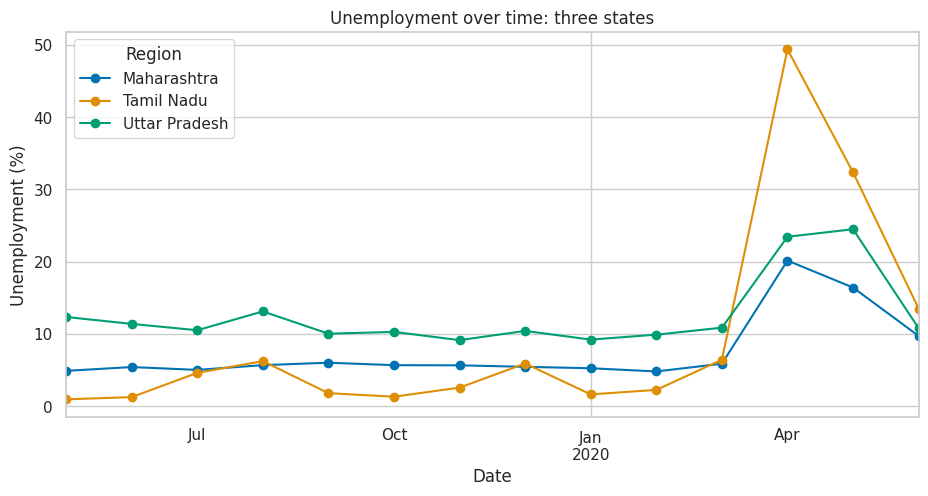

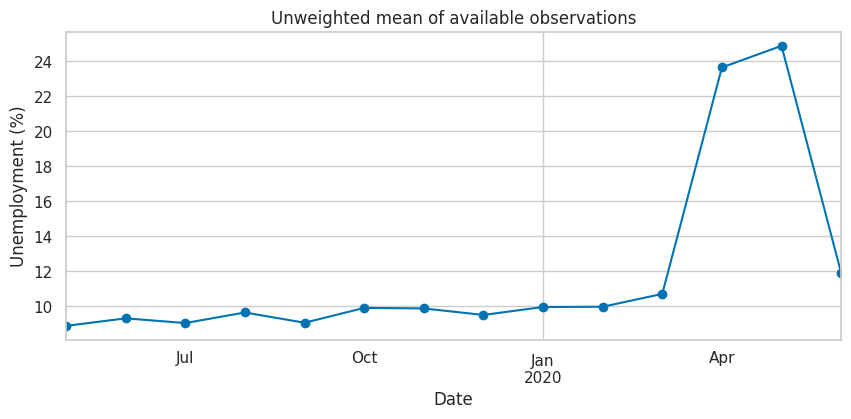

In [4]:
monthly=df.groupby('Date')[rate].mean();display(monthly.to_frame())
states=['Maharashtra','Tamil Nadu','Uttar Pradesh']
trends=df[df.Region.isin(states)].pivot_table(index='Date',columns='Region',values=rate,aggfunc='mean')
trends.plot(figsize=(11,5),marker='o',title='Unemployment over time: three states');plt.ylabel('Unemployment (%)');save('state_trends')
monthly.plot(figsize=(10,4),marker='o',title='Unweighted mean of available observations');plt.ylabel('Unemployment (%)');save('monthly_mean')
print('Peak observed month:',monthly.idxmax().date(),'Mean:',round(monthly.max(),2))

**Observation:** The three selected states show a sharp spring-2020 spike, with Tamil Nadu rising most sharply in the displayed comparison. The fall afterward does not imply a complete labour-market recovery.

## Relationships between rates
The dataset contains an employed **count**, not a supplied employment rate. We derive the employment-to-population rate as labour participation × (1 − unemployment/100), assuming consistent denominators. This mathematical dependence partly drives correlation; correlation is not causal evidence.

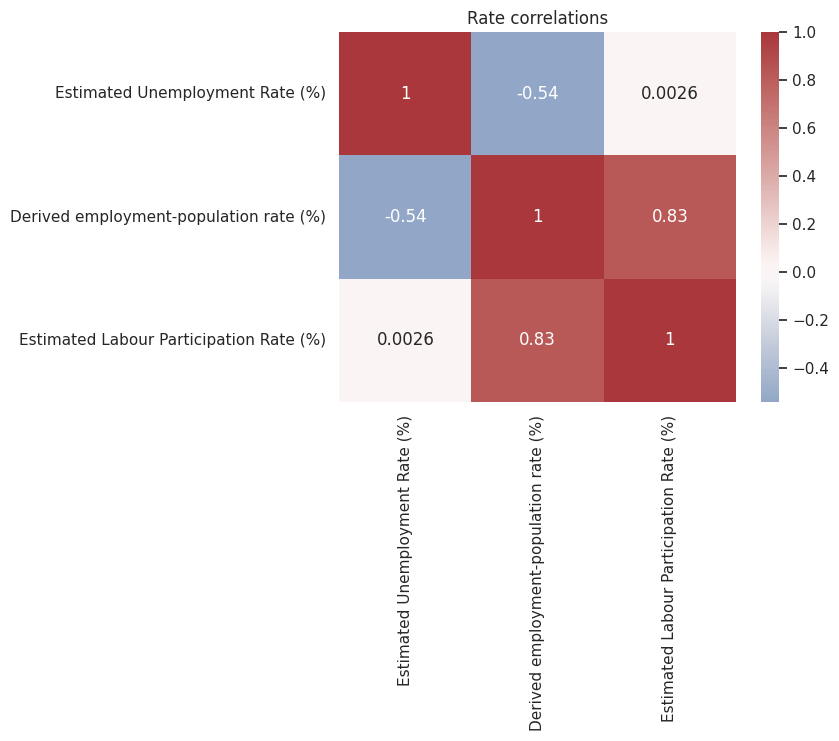

In [5]:
cols=[rate,'Derived employment-population rate (%)',participation]
sns.heatmap(df[cols].corr(),annot=True,cmap='vlag',center=0);plt.title('Rate correlations');save('correlation')

**Observation:** The derived employment-population rate is mathematically connected to unemployment and participation, so these correlations should not be presented as independent economic findings.

## Before versus during the COVID period
We use 1 April 2020 as the first full lockdown-era month, leave March out as a transition month, and compare against observations before March 2020. The later period is **during the pandemic**, not after the pandemic ended. This comparison cannot isolate COVID from other changes.

Change (percentage points): 10.68
Mean paired region-area change: 10.7


,mean,count
period,,
COVID period,20.194342,152
Pre-COVID,9.509534,536


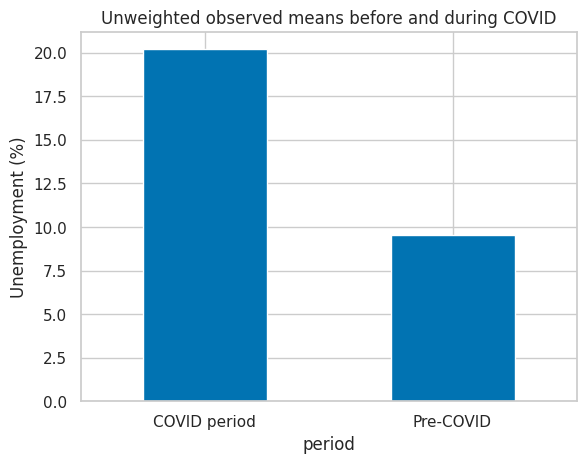

period                  COVID period  Pre-COVID  Change (pp)
Region           Area                                       
Andhra Pradesh   Rural     10.533333   4.171000     6.362333
                 Urban     21.023333   5.904000    15.119333
Assam            Rural      4.690000   4.526667     0.163333
                 Urban      7.520000   8.034000    -0.514000
Bihar            Rural     37.613333  10.655000    26.958333
                 Urban     36.363333  17.011000    19.352333
Chandigarh       Urban      7.220000  16.325000    -9.105000
Chhattisgarh     Rural      5.926667   6.771000    -0.844333
                 Urban     23.766667   8.642000    15.124667
Delhi            Rural     21.530000  13.385000     8.145000
                 Urban     26.800000  15.076000    11.724000
Goa              Rural     17.955000   6.477000    11.478000
                 Urban     11.760000  10.538000     1.222000
Gujarat          Rural      9.330000   4.726000     4.604000
                 Urban     14.033333   5.626000     8.407333
Haryana          Rural     37.133333  21.486000    15.647333
                 Urban     38.253333  24.385000    13.868333
Himachal Pradesh Rural      9.630000  17.046000    -7.416000
                 Urban     21.170000  21.212000    -0.042000
Jammu & Kashmir  Rural     10.595000  15.910000    -5.315000
                 Urban     12.960000  18.530000    -5.570000
Jharkhand        Rural     39.450000   8.974000    30.476000
                 Urban     50.343333  19.585000    30.758333
Karnataka        Rural     22.603333   3.094000    19.509333
                 Urban     15.706667   3.375000    12.331667
Kerala           Rural     20.583333   7.418000    13.165333
                 Urban     21.293333   6.567000    14.726333
Madhya Pradesh   Rural     13.806667   3.654000    10.152667
                 Urban     21.716667   5.828000    15.888667
Maharashtra      Rural     17.190000   3.839000    13.351000
                 Urban     13.640000   6.901000     6.739000
Meghalaya        Rural      4.486667   1.991000     2.495667
                 Urban     15.985000   6.015000     9.970000
Odisha           Rural     12.840000   3.897000     8.943000
                 Urban     10.893333   2.920000     7.973333
Puducherry       Rural     74.510000   1.034000    73.476000
                 Urban     52.096667   2.152000    49.944667
Punjab           Rural     21.426667   9.216000    12.210667
                 Urban     10.740000  12.773000    -2.033000
Rajasthan        Rural     12.186667  10.695000     1.491667
                 Urban     24.640000  14.819000     9.821000
Sikkim           Rural      2.905000   6.530000    -3.625000
                 Urban      9.383333   6.155000     3.228333
Tamil Nadu       Rural     31.326667   2.252000    29.074667
                 Urban     32.143333   3.421000    28.722333
Telangana        Rural     19.273333   4.664000    14.609333
                 Urban     17.996667   4.648000    13.348667
Tripura          Rural     25.730000  27.153000    -1.423000
                 Urban     26.376667  30.866000    -4.489333
Uttar Pradesh    Rural     15.106667   8.823000     6.283667
                 Urban     24.016667  12.415000    11.601667
Uttarakhand      Rural      5.980000   4.553000     1.427000
                 Urban     11.873333   7.050000     4.823333
West Bengal      Rural     13.896667   5.730000     8.166667
                 Urban     13.570000   7.410000     6.160000

In [6]:
df['period']=np.where(df.Date<pd.Timestamp('2020-03-01'),'Pre-COVID',np.where(df.Date>=pd.Timestamp('2020-04-01'),'COVID period','Transition'))
comparison=df[df.period!='Transition'].groupby('period')[rate].agg(['mean','count']);display(comparison)
comparison.to_csv(OUT/'period_comparison.csv')
comparison['mean'].plot.bar(rot=0,title='Unweighted observed means before and during COVID');plt.ylabel('Unemployment (%)');save('covid_comparison')
print('Change (percentage points):',round(comparison.loc['COVID period','mean']-comparison.loc['Pre-COVID','mean'],2))
# Paired regional comparison reduces changes from a different state mix.
paired=df[df.period!='Transition'].pivot_table(index=['Region','Area'],columns='period',values=rate).dropna()
paired['Change (pp)']=paired['COVID period']-paired['Pre-COVID'];display(paired);paired.to_csv(OUT/'paired_comparison.csv')
print('Mean paired region-area change:',round(paired['Change (pp)'].mean(),2))

## Interpretation
Read the printed peak month, ranking and percentage-point changes together with the charts. Changes are associations in a limited historical sample. Rural/urban coverage, labour-force exit and missing observations matter; a rise in unemployment is not a complete measure of labour-market hardship.

## Results from the verified run
The highest unweighted regional mean is Tripura (28.35%). The pre-COVID mean is 9.51% and the COVID-period mean is 20.19%, a change of 10.68 percentage points. These are sample means, not official national estimates.